In [2]:
from collections import defaultdict
import glob
import json

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from datetime import datetime, timedelta
from matplotlib.path import Path
import asf_search as asf
import pandas as pd
from cartopy.crs import NorthPolarStereo
from cartopy.feature import LAND

In [3]:
# Load the computed Sentinel-1 statistics and add a column for the month of each observation
df = pd.read_feather('s1_stats_from_cmems.feather')
df['m'] = [datetime.fromtimestamp(t).month for t in df.t]

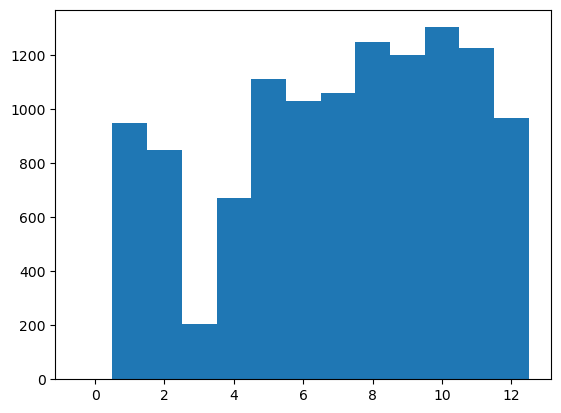

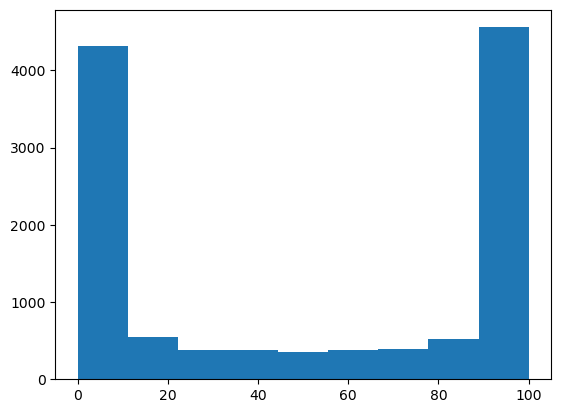

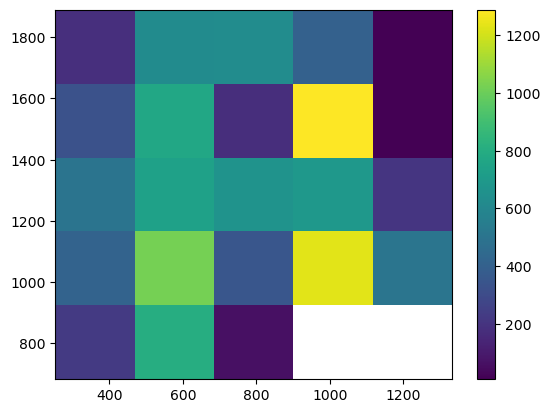

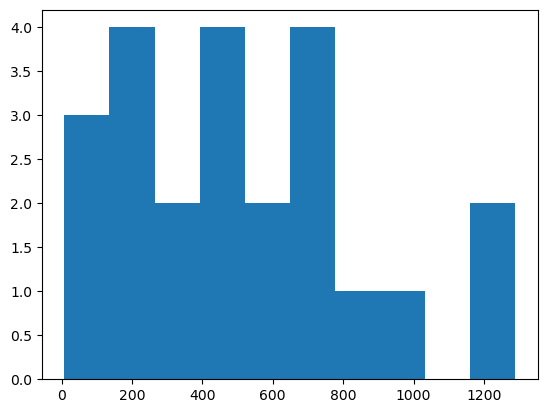

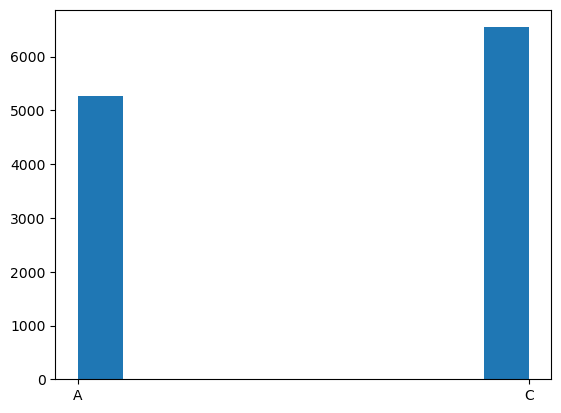

In [4]:
# Plot the statistics of ALL selected Sentine-1 scenes including: month of acquisition, sea ice concentration, pixel positions, and platform
# Histogram of the month of acquisition
bins2d = 5
plt.hist(df.m, bins=np.arange(-0.5,13.5,1))
plt.show()

# Histogram of the sea ice concentration
plt.hist(df.sic, bins=np.linspace(0,100,10))
plt.show()

# 2D histogram of pixel positions (column vs row)
pos_counts, _, _, _ = plt.hist2d(df.col, df.row, bins=bins2d, cmin=1)
plt.colorbar()
plt.show()

# histogram of the non-zero counts in the 2D pixel position histogram
plt.hist(pos_counts[pos_counts > 0])
plt.show()

# Histogram of the platform (assuming the platform information is stored in the third character of the scene name)
plt.hist(df.name.str[2].values)
plt.show()

In [5]:
# Sample the Sentinel-1 statistics to have a more balanced distribution of pixel positions
pos_counts, col_bins, row_bins, _ = plt.hist2d(df.col, df.row, bins=bins2d, cmin=1)
plt.close()

# Compute the median count of pixels per bin in the 2D histogram of pixel positions
med_count = np.percentile(pos_counts[pos_counts > 0], 50)
print(f'Median count per bin: {med_count}')
sampled_indices = []
# Loop through each bin in the 2D histogram and sample pixels to achieve a more balanced distribution
for r in range(pos_counts.shape[0]):
    for c in range(pos_counts.shape[1]):
        # Skip bins with zero counts
        if pos_counts[r, c] > 0:
            # Create a mask for the pixels that fall within the current bin
            mask = (df.col >= col_bins[c]) & (df.col < col_bins[c+1]) & (df.row >= row_bins[r]) & (df.row < row_bins[r+1])
            # Get the indices of the pixels within the current bin
            bin_indices = df[mask].index.tolist()
            # Determine the number of samples to draw from the current bin
            n_samples = min(len(bin_indices), int(med_count))
            # Sample the determined number of pixels from the current bin without replacement
            sampled_indices.extend(np.random.choice(bin_indices, n_samples, replace=False))
df2 = df.loc[sampled_indices]

# Compute the 2D histogram of the sampled pixel positions to verify the balanced distribution
pos_counts2, col_bins, row_bins, _ = plt.hist2d(df2.col, df2.row, bins=(col_bins, row_bins), cmin=1)
plt.close()

# Compute the median count of pixels per bin in the 2D histogram of the sampled pixel positions
med_count = np.percentile(pos_counts[pos_counts > 0], 50)
print(f'Median count per bin: {med_count}')

Median count per bin: 499.0
Median count per bin: 499.0


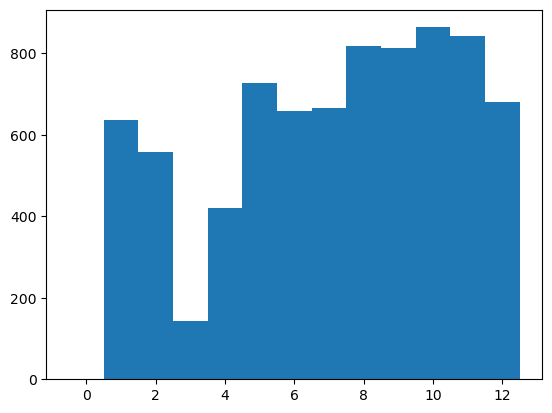

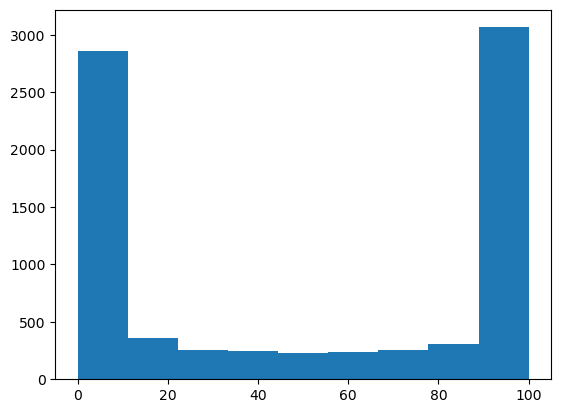

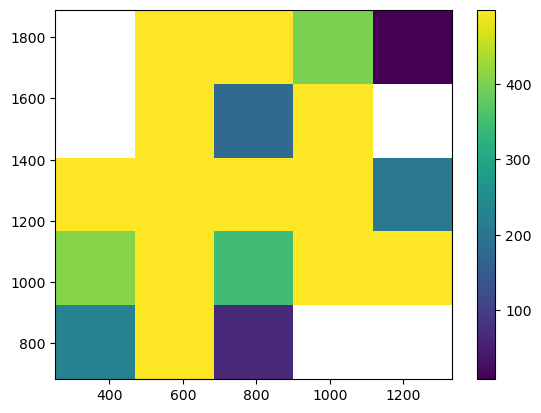

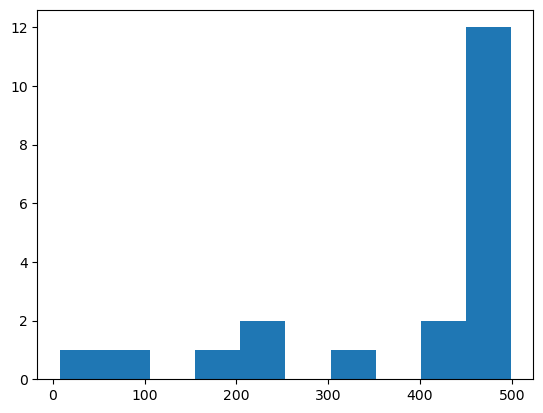

In [6]:
# Plot the statistics of the sampled Sentinel-1 scenes including: month of acquisition, sea ice concentration, and pixel positions
# Histogram of the month of acquisition
plt.hist(df2.m, bins=np.arange(-0.5,13.5,1))
plt.show()

# Histogram of the sea ice concentration
plt.hist(df2.sic, bins=np.linspace(0,100,10))
plt.show()

# 2D histogram of pixel positions (column vs row)
pos_counts, _, _, _ = plt.hist2d(df2.col, df2.row, bins=(col_bins, row_bins), cmin=1)
plt.colorbar()
plt.show()

# Histogram of the non-zero counts in the 2D pixel position histogram
plt.hist(pos_counts[pos_counts > 0])
plt.show()


Median count per bin: 257.0
Median count per bin after sampling: 257.0


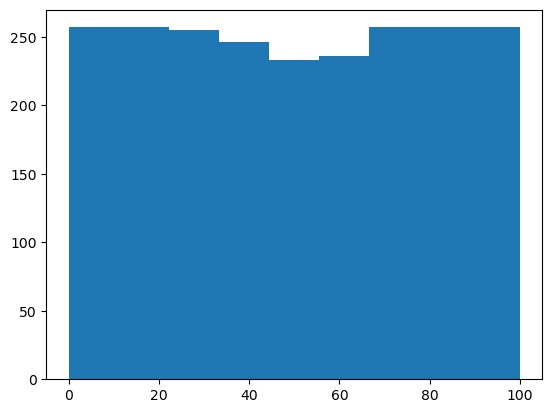

In [7]:
# Sample the Sentinel-1 statistics to have a more balanced distribution of sea ice concentration
# Compute the histogram of sea ice concentration and determine the median count per bin
# Loop through each bin and sample pixels to achieve a more balanced distribution
sic_counts, sic_bins = np.histogram(df2.sic.dropna(), bins=np.linspace(0, 100, 10))
med_count = np.median(sic_counts)
print(f'Median count per bin: {med_count}')
sampled_indices = []
for i in range(len(sic_counts)):
    mask = (df2.sic >= sic_bins[i]) & (df2.sic < sic_bins[i+1])
    bin_indices = df2[mask].index.tolist()
    n_samples = min(len(bin_indices), int(med_count))
    sampled_indices.extend(np.random.choice(bin_indices, n_samples, replace=False))

df3 = df2.loc[sampled_indices]
df3.shape

# Compute the histogram of sea ice concentration for the sampled data
sic_counts3, sic_bins3 = np.histogram(df3.sic.dropna(), bins=np.linspace(0, 100, 10))
print(f'Median count per bin after sampling: {np.median(sic_counts3)}')

# Plot the histogram of sea ice concentration for the sampled data
plt.hist(df3.sic.dropna(), bins=np.linspace(0, 100, 10))
plt.show()

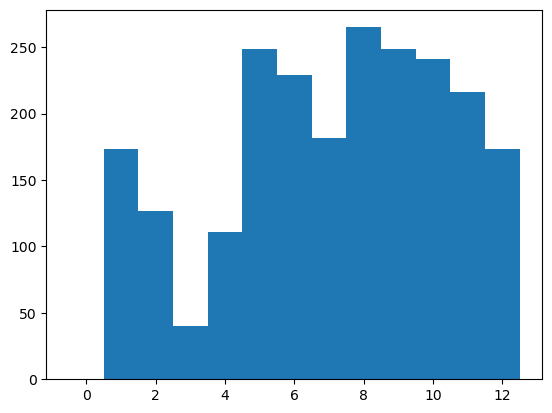

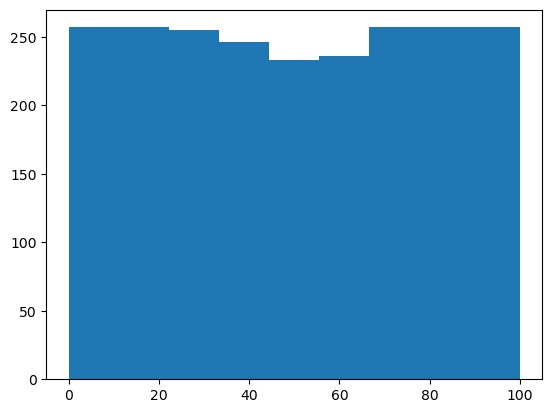

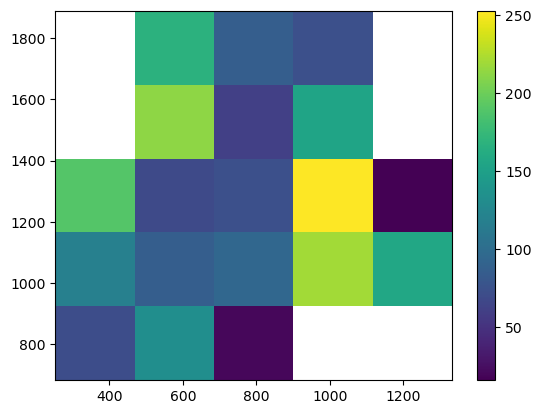

In [8]:
# Histogram of the month of acquisition for the sampled data
plt.hist(df3.m, bins=np.arange(-0.5,13.5,1))
plt.show()

# Histogram of the sea ice concentration for the sampled data
plt.hist(df3.sic, bins=np.linspace(0,100,10))
plt.show()

# 2D histogram of pixel positions for the sampled data
plt.hist2d(df3.col, df3.row, bins=(col_bins, row_bins), cmin=1)
plt.colorbar()
plt.show()

In [13]:
# Read the ASIP sea ice concentration mosaic data
asip_file_path = '/Volumes/KINGSTON//dmi_asip/SEAICE_ARC_PHY_AUTO_L3_MYNRT_011_023/cmems_obs-si_arc_phy_nrt_l3_P1D_202411/2025/04/dmi_asip_seaice_mosaic_arc_l3_20250401.nc'
with xr.open_dataset(asip_file_path) as ds:
    # Subsample the coordinate grids for faster processing
    xc = ds['xc'][::10].values
    yc = ds['yc'][::10].values    

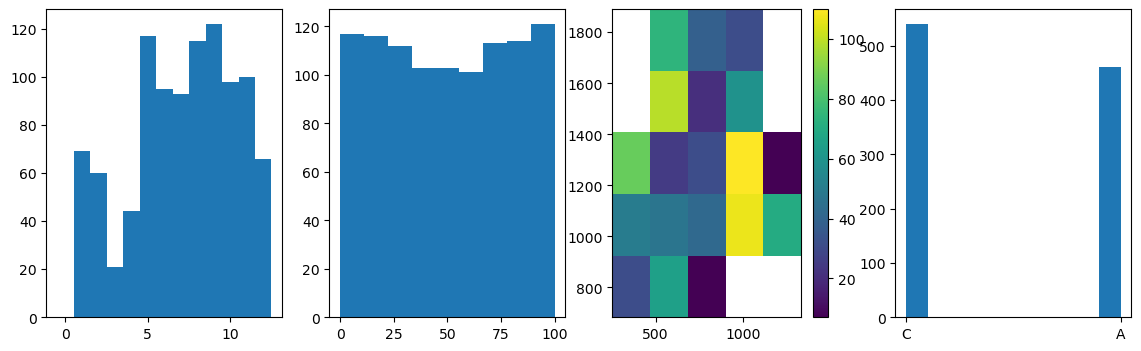

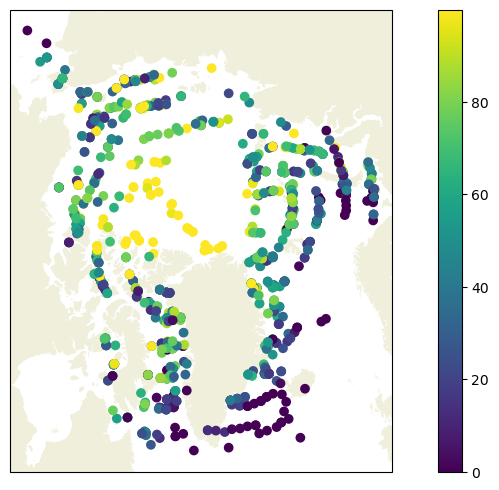

In [14]:
# Sample 1000 pixels from the previously sampled data for visualization
df4 = df3.sample(n=1000)

# Plot the statistics of the sampled pixels including: month of acquisition, sea ice concentration, pixel positions, and scene names
fig, axs = plt.subplots(1, 4, figsize=(14, 4))
axs[0].hist(df4.m, bins=np.arange(-0.5,13.5,1))
axs[1].hist(df4.sic, bins=np.linspace(0,100,10))
_, _, _, hist = axs[2].hist2d(df4.col, df4.row, bins=(col_bins, row_bins), cmin=1)
plt.colorbar(hist, ax=axs[2])
axs[3].hist(df4.name.str[2].values)
plt.show()

x = df4.col / (xc.size - 1) * (xc.max() - xc.min()) + xc.min()
y = yc.max() - df4.row / (yc.size - 1) * (yc.max() - yc.min())

# Plot a scatter plot of the sampled pixels on the North Polar Stereo projection with intensity representing sea ice concentration
fig, ax = plt.subplots(1, 1, figsize=(12, 6), subplot_kw={'projection': NorthPolarStereo(central_longitude=-45)})
scat = ax.scatter(x, y, c=df4.sic)
ax.add_feature(LAND)
plt.colorbar(scat)
plt.show()

In [ ]:
# Save the sorted scene names to a CSV file
df4.name.sort_values().to_csv('s1_names.csv', index=False)